# 04 - Baseline IDS Modeling (Member 3)

**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*

This notebook trains and compares **baseline intrusion-detection models** on the common evaluation population `Multimodal Datasets/multimodal_dataset_v2.csv`
(network + radio windows aligned at the **UTC-second level only**; no packet-to-UE correspondence is claimed).

| | Experiment | Features |
|---|---|---|
| **A** | Network-only | the 29 approved network features |
| **B** | Radio-only | the 32 approved radio **Profile A** (conservative core) features |
| **C** | Multimodal | A + B = 61 features |

* **Target:** `is_attack` (0 = Benign, **1 = Attack = positive class**). `class_fm` is used only for optional exploratory analysis.
* **Split:** one scenario-grouped, stratified train/validation/test split (about 64/16/20), identical for all three experiments. Never row-random.
* **Models:** Logistic Regression, Random Forest, XGBoost (if installed). Imputation/scaling are fitted on training data only (inside each `Pipeline`).
* **Selection:** per modality, using **validation** performance only. The test partition is evaluated once, after the selection is frozen.

**Out of scope here (other team members):** telemetry manipulation, adversarial simulation, trust scoring, sensor-reliability mechanisms, defenses.
Results are **dataset-specific baseline performance**, not evidence of generalisation to unseen 5G deployments (see the limitations in `Results/baseline_report.md`).

In [1]:
# ---- 0. Setup: paths, seeds, dependency/version checks -----------------------------------------------------------
import sys, os, json, time, platform, hashlib, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import scipy, sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score, confusion_matrix,
                             classification_report, log_loss)
from IPython.display import display

sys.dont_write_bytecode = True
SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.environ.setdefault("PYTHONHASHSEED", str(SEED))

# optional dependency
try:
    import xgboost
    from xgboost import XGBClassifier
    HAS_XGB, XGB_ERR = True, ""
except Exception as e:            # not installed, or a native-library problem
    xgboost, HAS_XGB, XGB_ERR = None, False, repr(e)

def _ver(v): return tuple(int(x) for x in v.split(".")[:2])
MIN_VERSIONS = {"numpy": "1.22", "pandas": "1.5", "scikit-learn": "1.2", "matplotlib": "3.5", "joblib": "1.1", "scipy": "1.8"}
FOUND = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
         "matplotlib": matplotlib.__version__, "joblib": joblib.__version__, "scipy": scipy.__version__}
for pkg, need in MIN_VERSIONS.items():
    assert _ver(FOUND[pkg]) >= _ver(need), f"{pkg} {FOUND[pkg]} is older than the required {need}"
ENV_TABLE = pd.DataFrame([{"package": k, "version": v, "minimum": MIN_VERSIONS[k], "ok": _ver(v) >= _ver(MIN_VERSIONS[k])} for k, v in FOUND.items()]
                         + [{"package": "xgboost (optional)", "version": xgboost.__version__ if HAS_XGB else "NOT AVAILABLE", "minimum": "1.7",
                             "ok": HAS_XGB and _ver(xgboost.__version__) >= (1, 7)}])
print(f"python {platform.python_version()} on {platform.system()} | seed {SEED}")
display(ENV_TABLE)
if not HAS_XGB:
    print("XGBoost is not available -> the XGBoost experiments are SKIPPED and the report will say so.", XGB_ERR)

# project root (works when run from the root or from a sub-folder)
ROOT = Path.cwd()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "Multimodal Datasets" / "multimodal_dataset_v2.csv").exists():
        ROOT = cand; break
else:
    raise FileNotFoundError("Project root not found: expected 'Multimodal Datasets/multimodal_dataset_v2.csv'")
P = {
    "mm": ROOT / "Multimodal Datasets" / "multimodal_dataset_v2.csv",
    "mm_json": ROOT / "Multimodal Datasets" / "multimodal_feature_columns_v2.json",
    "net": ROOT / "Network Dataset" / "network_clean.csv",
    "net_json": ROOT / "Network Dataset" / "network_feature_columns.json",
    "radio": ROOT / "Radio Dataset" / "radio_window_features_v2.csv",
    "radio_json": ROOT / "Radio Dataset" / "radio_feature_columns_v2.json",
}
MODELS_DIR, RESULTS_DIR = ROOT / "Models", ROOT / "Results"
NEW_ARTIFACT_NAMES = {"04_baseline_models.ipynb"}
for k, p in P.items():
    assert p.exists(), f"missing input: {p}"
MODELS_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)
print("project root:", ROOT)

# Manifest of every pre-existing repository file (to prove at the end that nothing of Member 1/2 was touched)
def _sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def _tracked():
    skip = {"Models", "Results", "__pycache__", ".git", ".ipynb_checkpoints"}
    return sorted(p for p in ROOT.rglob("*") if p.is_file() and not (skip & set(p.relative_to(ROOT).parts))
                  and p.name not in NEW_ARTIFACT_NAMES)
MANIFEST_BEFORE = {str(p.relative_to(ROOT)): _sha(p) for p in _tracked()}
print("pre-existing project files hashed:", len(MANIFEST_BEFORE))

python 3.12.3 on Linux | seed 42


,package,version,minimum,ok
0,numpy,2.5.4,1.22,True
1,pandas,3.0.6,1.5,True
2,scikit-learn,1.9.1,1.2,True
3,matplotlib,3.11.2,3.5,True
4,joblib,1.6.0,1.1,True
5,scipy,1.18.1,1.8,True
6,xgboost (optional),3.4.1,1.7,True


project root: <redacted local path>
pre-existing project files hashed: 32


## 1. Inspect and verify the inputs

Column names, feature lists, labels, scenario identifiers and missing values are **checked against the files**, not assumed.
The approved feature lists are read from the JSON schemas written by Member 1 / Member 2, and the multimodal columns are cross-checked against the two source tables.

In [2]:
# ---- 1. Load and verify -----------------------------------------------------------------------------------------
df = pd.read_csv(P["mm"])
net_src = pd.read_csv(P["net"]); radio_src = pd.read_csv(P["radio"])
net_meta = json.load(open(P["net_json"], encoding="utf-8"))
radio_meta = json.load(open(P["radio_json"], encoding="utf-8"))
mm_meta = json.load(open(P["mm_json"], encoding="utf-8"))

NET_FEATURES   = list(net_meta["feature_cols"])                                    # approved network features
RADIO_FEATURES = list(radio_meta["model_feature_profiles"]["A_conservative_core"])   # radio Profile A (primary)
MM_FEATURES    = list(mm_meta["profiles"]["A"]["columns"])                           # multimodal Profile A
FEATURE_SETS = {"network": NET_FEATURES, "radio": RADIO_FEATURES, "multimodal": NET_FEATURES + RADIO_FEATURES}
MODALITIES = list(FEATURE_SETS)
TARGET = "is_attack"

checks_load = {
    "29 network features": len(NET_FEATURES) == 29,
    "32 radio Profile A features": len(RADIO_FEATURES) == 32,
    "61 multimodal features": len(FEATURE_SETS["multimodal"]) == 61,
    "multimodal list == multimodal_feature_columns_v2.json Profile A": FEATURE_SETS["multimodal"] == MM_FEATURES,
    "no duplicate feature names": len(set(MM_FEATURES)) == len(MM_FEATURES),
    "network / radio feature names disjoint": not (set(NET_FEATURES) & set(RADIO_FEATURES)),
    "all features present in multimodal_dataset_v2.csv": set(MM_FEATURES) <= set(df.columns),
    "all features numeric": all(pd.api.types.is_numeric_dtype(df[c]) for c in MM_FEATURES),
    "no +/-inf in features": not np.isinf(df[MM_FEATURES].to_numpy(dtype=float)).any(),
    "no constant feature": all(df[c].nunique(dropna=True) > 1 for c in MM_FEATURES),
    "target is 0/1 with no nulls": set(df[TARGET].unique()) <= {0, 1} and df[TARGET].notna().all(),
    "scenario has no nulls": df["scenario"].notna().all(),
    "label constant within every scenario": bool((df.groupby("scenario")[TARGET].nunique() == 1).all()),
    "window_id unique (stable sample id)": df["window_id"].is_unique,
    "multimodal rows == matched keys documented (window_id unique, 1 row per window)": len(df) == df["window_id"].nunique(),
}
# provenance: the approved feature VALUES equal the source tables' values (join was a pure lookup)
src_n = net_src.set_index("window_id")[NET_FEATURES].reindex(df["window_id"]).reset_index(drop=True)
checks_load["network feature values identical to network_clean.csv"] = bool(np.allclose(df[NET_FEATURES].to_numpy(float), src_n.to_numpy(float), equal_nan=True))
rk = radio_src.assign(_k=list(zip(radio_src["scenario"].str.replace(r"^DDOS_", "DDOS", regex=True), radio_src["timestamp_s"]))).set_index("_k")
src_r = rk.reindex(list(zip(df["scenario"], df["timestamp_s"])))[RADIO_FEATURES].reset_index(drop=True)
checks_load["radio Profile A values identical to radio_window_features_v2.csv"] = bool(np.allclose(df[RADIO_FEATURES].to_numpy(float), src_r.to_numpy(float), equal_nan=True))
display(pd.Series(checks_load, name="passed").to_frame())
assert all(checks_load.values()), [k for k, v in checks_load.items() if not v]

print(f"\nevaluation population: {len(df):,} windows x {df.shape[1]} columns, {df['scenario'].nunique()} scenarios")
print("class balance (1 = Attack):", df[TARGET].value_counts().sort_index().to_dict(), f"| attack share {df[TARGET].mean():.3f}")
print("missing values in approved features:", {k: int(v) for k, v in df[MM_FEATURES].isna().sum().items() if v},
      "| rows with any:", int(df[MM_FEATURES].isna().any(axis=1).sum()), "| scenarios:", df.loc[df[MM_FEATURES].isna().any(axis=1), "scenario"].unique().tolist())
display(pd.crosstab(df["class_fm"], df[TARGET]).rename(columns={0: "Benign (0)", 1: "Attack (1)"}))

,passed
29 network features,True
32 radio Profile A features,True
61 multimodal features,True
multimodal list == multimodal_feature_columns_v2.json Profile A,True
no duplicate feature names,True
network / radio feature names disjoint,True
all features present in multimodal_dataset_v2.csv,True
all features numeric,True
no +/-inf in features,True
no constant feature,True



evaluation population: 4,139 windows x 86 columns, 35 scenarios
class balance (1 = Attack): {0: 1184, 1: 2955} | attack share 0.714
missing values in approved features: {'puschSnr_mean': 2, 'puschSnr_std': 2, 'puschSnr_min': 2, 'puschSnr_max': 2} | rows with any: 2 | scenarios: ['DDOSICMP2']


is_attack,Benign (0),Attack (1)
class_fm,,
Benign,1184,0
ICMP_DDoS,0,318
ICMP_DoS,0,350
PortScan,0,8
SYN_DDoS,0,314
SYN_DoS,0,362
TCP_DDoS,0,315
TCP_DoS,0,362
UDP_DDoS,0,316


## 2. Leakage guard

Only the three approved lists may be used. A guard rejects any column that is a label, scenario/identifier, time/epoch/date/session metadata, a diagnostic, a radio quality flag, a raw counter delta,
an `_nz` variant, or a held-out/sensitivity-only radio column. The guard is applied to the feature lists, **and** to the fitted pipelines at the very end.
(The network column `bytes` is an approved per-window packet-volume feature of the network sensor; it is *not* a radio byte counter.)

In [3]:
# ---- 2. Leakage guard -------------------------------------------------------------------------------------------
FORBIDDEN_EXACT = {
    "is_attack", "class_fm", "family", "mode", "ddos", "scenario", "radio_scenario", "window_id", "radio_window_id",
    "timestamp_s", "window_start_epoch_utc", "window_start_utc", "window_start_wall_epoch", "t_rel_s", "tz_label", "tz_offset_assumed_s",
    "is_partial", "coverage_s", "radio_n_records", "radio_n_ue_reporting", "radio_pusch_valid_reports",
    "diag_ttl_mean", "diag_tcp_win_mean", "row_index", "sample_id", "partition", "split",
}
FORBIDDEN_SUBSTRINGS = ["_nz", "Bytes", "_delta", "scenario", "timestamp", "epoch", "date", "tz_", "session", "capture",
                        "n_q_", "n_oob_", "_flag_", "diag_", "window_id", "class_", "label", "partition", "split_"]
# columns the radio/multimodal metadata explicitly keep OUT of the profiles
FORBIDDEN_BY_METADATA = (set(radio_meta["held_out_features"]["columns"]) | set(radio_meta["sensitivity_only_features"]["columns"])
                         | set(radio_meta["quality_flags"]["columns"]) | set(radio_meta["diagnostic_features"]["columns"])
                         | set(radio_meta["labels"]["columns"]) | set(net_meta["diag_cols_not_for_models"]) | set(net_meta["meta_cols"]))

def leakage_problems(features):
    bad = []
    for c in features:
        if c in FORBIDDEN_EXACT or c in FORBIDDEN_BY_METADATA or any(s in c for s in FORBIDDEN_SUBSTRINGS):
            bad.append(c)
    return sorted(set(bad))

for name, feats in FEATURE_SETS.items():
    prob = leakage_problems(feats)
    print(f"{name:11s}: {len(feats):2d} features | forbidden columns found: {prob if prob else 'none'}")
    assert not prob, prob

# self-test: the guard must actually reject forbidden columns
for injected in ["scenario", "timestamp_s", "class_fm", "is_attack", "dlBytes_delta_sum", "rsrp_mean", "puschSnr_mean_nz", "n_q_pusch_saturated",
                 "diag_ttl_mean", "radio_n_ue_reporting", "window_start_utc", "phr_mean"]:
    assert leakage_problems(FEATURE_SETS["multimodal"] + [injected]) == [injected], injected
print("guard self-test: all injected forbidden columns were rejected")

network    : 29 features | forbidden columns found: none


radio      : 32 features | forbidden columns found: none
multimodal : 61 features | forbidden columns found: none
guard self-test: all injected forbidden columns were rejected


## 3. Scenario-grouped, stratified train / validation / test split

**Rules:** all windows of a scenario stay in exactly one partition; the same split is used by all three experiments; no row-random fallback.

**Method.** `StratifiedGroupKFold` (stratified on `is_attack`, grouped by `scenario`) is applied twice: an outer 5-fold split gives the test partition (about 20%), and an inner 5-fold split of the remainder
gives the validation partition (about 16% of the total). Several seeds and fold choices are enumerated, and **the split is chosen by a split-quality score that uses only partition sizes and labels - no model is trained or evaluated
when choosing it**:

* *hard constraints:* both classes present in every partition; at least one Benign scenario in every partition; validation and test each contain at least one DoS **and** one DDoS attack scenario (so evaluation is not about one attack mode only);
* *score (lower is better):* `|test share - 0.20| + |val share - 0.16| + 0.5 * sum(|attack share of partition - overall attack share|)`;
* ties are broken by (seed, outer fold, inner fold), ascending.

`mode` (Benign / DoS / DDoS / PortScan) is used here only for the coverage constraint; it is never a model input.

In [4]:
# ---- 3. Split design (labels and sizes only; no model involved) -----------------------------------------------------
TARGET_FRAC = {"train": 0.64, "validation": 0.16, "test": 0.20}
SEARCH_SEEDS = list(range(50)); N_OUTER, N_INNER = 5, 5

y_all = df[TARGET].to_numpy(); groups_all = df["scenario"].to_numpy(); n_all = len(df)
scn_mode = df.groupby("scenario")["mode"].first().to_dict()
attack_share_all = y_all.mean()

def iter_candidate_splits():
    X0 = np.zeros(n_all)
    for seed in SEARCH_SEEDS:
        outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=seed)
        for fo, (rest, te) in enumerate(outer.split(X0, y_all, groups_all)):
            inner = StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=seed)
            for fi, (tr_rel, va_rel) in enumerate(inner.split(np.zeros(len(rest)), y_all[rest], groups_all[rest])):
                yield seed, fo, fi, rest[tr_rel], rest[va_rel], te

def score_candidate(tr, va, te):
    parts = {"train": tr, "validation": va, "test": te}
    info = {}
    for nm, idx in parts.items():
        yy = y_all[idx]; scn = set(groups_all[idx])
        info[nm] = dict(frac=len(idx) / n_all, attack_share=yy.mean(), n_benign=int((yy == 0).sum()),
                        benign_scn=sum(1 for s in scn if scn_mode[s] == "Benign"),
                        has_dos=any(scn_mode[s] == "DoS" for s in scn), has_ddos=any(scn_mode[s] == "DDoS" for s in scn))
    ok = all(0 < v["attack_share"] < 1 and v["benign_scn"] >= 1 for v in info.values())
    ok = ok and all(info[p]["has_dos"] and info[p]["has_ddos"] for p in ("validation", "test"))
    loss = (abs(info["test"]["frac"] - TARGET_FRAC["test"]) + abs(info["validation"]["frac"] - TARGET_FRAC["validation"])
            + 0.5 * sum(abs(v["attack_share"] - attack_share_all) for v in info.values()))
    return ok, loss

rows = []
for seed, fo, fi, tr, va, te in iter_candidate_splits():
    ok, loss = score_candidate(tr, va, te)
    rows.append((loss, seed, fo, fi, ok, tr, va, te))
n_cand = len(rows); feasible = sorted([r for r in rows if r[4]], key=lambda r: (r[0], r[1], r[2], r[3]))
assert feasible, "No grouped split satisfies the constraints - document and stop; do NOT fall back to a row-random split."
loss, SPLIT_SEED, OUTER_FOLD, INNER_FOLD, _, idx_tr, idx_va, idx_te = feasible[0]
distinct = {(tuple(sorted(set(groups_all[r[6]]))), tuple(sorted(set(groups_all[r[7]])))) for r in feasible}
print(f"candidates enumerated: {n_cand} | satisfying the hard constraints: {len(feasible)} | distinct (val, test) scenario assignments among them: {len(distinct)}")
print(f"chosen: seed={SPLIT_SEED}, outer fold={OUTER_FOLD}, inner fold={INNER_FOLD}, split-quality score={loss:.4f}")

PARTITION = np.empty(n_all, dtype=object)
PARTITION[idx_tr], PARTITION[idx_va], PARTITION[idx_te] = "train", "validation", "test"
assert (PARTITION != None).all()
SPLIT_FINGERPRINT = hashlib.sha256("".join(PARTITION).encode()).hexdigest()

manifest = pd.DataFrame({"row_index": np.arange(n_all), "sample_id": df["window_id"].to_numpy(), "scenario": df["scenario"].to_numpy(),
                         "partition": PARTITION, "is_attack": y_all, "class_fm": df["class_fm"].to_numpy(), "mode": df["mode"].to_numpy(),
                         "split_seed": SPLIT_SEED, "outer_fold": OUTER_FOLD, "inner_fold": INNER_FOLD})
manifest.to_csv(RESULTS_DIR / "split_manifest.csv", index=False, lineterminator="\n")

# ---- integrity checks on the split ---------------------------------------------------------------------------
scn_sets = {p: set(manifest.loc[manifest.partition == p, "scenario"]) for p in TARGET_FRAC}
split_checks = {
    "every row assigned to exactly one partition": manifest["partition"].isin(list(TARGET_FRAC)).all() and len(manifest) == n_all,
    "no scenario in more than one partition": not (scn_sets["train"] & scn_sets["validation"] or scn_sets["train"] & scn_sets["test"] or scn_sets["validation"] & scn_sets["test"]),
    "every scenario assigned": set().union(*scn_sets.values()) == set(df["scenario"]),
    "both classes in every partition": all(manifest.loc[manifest.partition == p, "is_attack"].nunique() == 2 for p in TARGET_FRAC),
    "at least one Benign scenario in every partition": all(any(scn_mode[s] == "Benign" for s in scn_sets[p]) for p in TARGET_FRAC),
}
display(pd.Series(split_checks, name="passed").to_frame()); assert all(split_checks.values())

def partition_table(m):
    t = m.groupby("partition").agg(scenarios=("scenario", "nunique"), windows=("row_index", "size"), benign_windows=("is_attack", lambda s: int((s == 0).sum())),
                                   attack_windows=("is_attack", lambda s: int((s == 1).sum()))).reindex(list(TARGET_FRAC))
    t["share_of_windows"] = (t["windows"] / t["windows"].sum()).round(4); t["attack_share"] = (t["attack_windows"] / t["windows"]).round(4)
    t["benign_scenarios"] = [sum(1 for s in scn_sets[p] if scn_mode[s] == "Benign") for p in t.index]
    t["target_share"] = [TARGET_FRAC[p] for p in t.index]
    return t
PART_TABLE = partition_table(manifest); display(PART_TABLE)
CLASS_BY_PART = pd.crosstab(manifest["class_fm"], manifest["partition"])[list(TARGET_FRAC)]; display(CLASS_BY_PART)
SCN_ASSIGN = (manifest.groupby("scenario").agg(partition=("partition", "first"), class_fm=("class_fm", "first"), mode=("mode", "first"), windows=("row_index", "size"))
              .join(df.assign(_d=pd.to_datetime(df["timestamp_s"], unit="s", utc=True).dt.strftime("%Y-%m-%d")).groupby("scenario")["_d"].first().rename("capture_date_utc"))
              .reset_index().sort_values(["partition", "class_fm", "scenario"]))
display(SCN_ASSIGN)

candidates enumerated: 1250 | satisfying the hard constraints: 1200 | distinct (val, test) scenario assignments among them: 1133
chosen: seed=0, outer fold=0, inner fold=1, split-quality score=0.0177


,passed
every row assigned to exactly one partition,True
no scenario in more than one partition,True
every scenario assigned,True
both classes in every partition,True
at least one Benign scenario in every partition,True


,scenarios,windows,benign_windows,attack_windows,share_of_windows,attack_share,benign_scenarios,target_share
partition,,,,,,,,
train,22,2702,778,1924,0.6528,0.7121,4,0.64
validation,6,635,177,458,0.1534,0.7213,1,0.16
test,7,802,229,573,0.1938,0.7145,1,0.20


partition,train,validation,test
class_fm,,,
Benign,778,177,229
ICMP_DDoS,210,108,0
ICMP_DoS,350,0,0
PortScan,2,4,2
SYN_DDoS,213,101,0
SYN_DoS,241,0,121
TCP_DDoS,108,0,207
TCP_DoS,119,124,119
UDP_DDoS,316,0,0


,scenario,partition,class_fm,mode,windows,capture_date_utc
3,Benign4,test,Benign,Benign,229,2025-04-14
21,PortScan1,test,PortScan,PortScan,2,2025-02-27
25,SYN2,test,SYN_DoS,DoS,121,2025-03-06
12,DDOSTCP1,test,TCP_DDoS,DDoS,100,2025-04-03
13,DDOSTCP2,test,TCP_DDoS,DDoS,107,2025-04-03
29,TCP3,test,TCP_DoS,DoS,119,2025-03-06
32,UDP3,test,UDP_DoS,DoS,124,2025-03-06
0,Benign1,train,Benign,Benign,121,2025-04-14
1,Benign2,train,Benign,Benign,235,2025-04-14
4,Benign5,train,Benign,Benign,152,2025-04-14


## 4. Descriptive screen for label-proxy features (training partition only)

The approved lists are used as they are. This screen only **describes** how strongly individual features separate the classes **in the training partition** (symmetric single-feature ROC-AUC),
because a near-perfect single feature would explain very high model scores without any attack-specific learning. No feature is removed because of it, and no test data is used.

In [5]:
# ---- 4. Single-feature separability screen (TRAIN only; descriptive) --------------------------------------------
from scipy.stats import rankdata
def sym_auc(x, y):
    m = ~np.isnan(x); x, y = x[m], y[m]
    r = rankdata(x); n1 = (y == 1).sum(); n0 = (y == 0).sum()
    a = (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return max(a, 1 - a)
tr_mask = manifest["partition"].to_numpy() == "train"
SCREEN = pd.DataFrame({"feature": MM_FEATURES,
                       "modality": ["network" if c in NET_FEATURES else "radio" for c in MM_FEATURES],
                       "train_single_feature_auc": [sym_auc(df.loc[tr_mask, c].to_numpy(float), y_all[tr_mask]) for c in MM_FEATURES]})
SCREEN_SUMMARY = SCREEN.groupby("modality")["train_single_feature_auc"].agg(features="size", median="median", maximum="max",
                                                                          n_ge_099=lambda s: int((s >= 0.99).sum())).round(4)
display(SCREEN_SUMMARY)
display(SCREEN.sort_values("train_single_feature_auc", ascending=False).head(8).round(4))

,features,median,maximum,n_ge_099
modality,,,,
network,29,0.745,0.9955,1
radio,32,0.619,0.9613,0


,feature,modality,train_single_feature_auc
17,tcp_payload_mean,network,0.9955
27,top_dst_share,network,0.9677
31,rsrq_min,radio,0.9613
6,burst_cv,network,0.9398
42,dlBler_std,radio,0.9371
29,rsrq_mean,radio,0.9354
16,ackonly_frac,network,0.9349
30,rsrq_std,radio,0.9317


## 5. Models, preprocessing and validation-based tuning

| Model | Pipeline (all fitted on **training** data only) | Search space (small, because of the deadline) |
|---|---|---|
| Logistic Regression | median imputer -> standard scaler -> LR (`class_weight="balanced"`, L2) | `C` in {0.01, 0.1, 1, 10} |
| Random Forest | median imputer -> RF (300 trees, `class_weight="balanced_subsample"`) | `max_depth` in {5, 10, None} x `min_samples_leaf` in {1, 5} |
| XGBoost | median imputer -> XGBClassifier (200 trees, `scale_pos_weight` = train benign/attack ratio) | `max_depth` in {3, 5} x `learning_rate` in {0.05, 0.1} |

The imputer is inside each pipeline, so the median is learned from the training rows only (no global imputation); the few missing PUSCH-SNR statistics are filled with the training median at predict time.
Class imbalance (attack is the majority class) is handled with class weights. The decision threshold is fixed at **0.5** (not tuned).

**Selection criterion (validation only), applied to hyper-parameters within a model family and then to the families within a modality:**
validation macro-F1 (higher) -> validation PR-AUC (higher) -> validation FPR (lower) -> validation log-loss (lower) -> fixed grid order (LR < RF < XGBoost).
The test partition is not touched until the selection is frozen.

In [6]:
# ---- 5. Modeling functions ---------------------------------------------------------------------------------------
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
THRESHOLD = 0.5
MODEL_ORDER = ["LogisticRegression", "RandomForest"] + (["XGBoost"] if HAS_XGB else [])
MODEL_SHORT = {"LogisticRegression": "LR", "RandomForest": "RF", "XGBoost": "XGB"}

def compute_metrics(y, p, thr=THRESHOLD):
    """Attack (1) is the positive class. FPR = FP / (FP + TN): share of benign windows flagged as attack."""
    y = np.asarray(y); p = np.asarray(p, float); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"macro_f1": f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0),
            "precision": precision_score(y, pred, pos_label=1, zero_division=0),
            "recall": recall_score(y, pred, pos_label=1, zero_division=0),
            "f1_attack": f1_score(y, pred, pos_label=1, zero_division=0),
            "pr_auc": average_precision_score(y, p),
            "fpr": fp / (fp + tn) if (fp + tn) else float("nan"),
            "accuracy": float((pred == y).mean()),
            "log_loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15), labels=[0, 1]),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def build_pipeline(name, params, scale_pos_weight=1.0):
    imputer = SimpleImputer(strategy="median")
    if name == "LogisticRegression":
        clf = LogisticRegression(C=params["C"], class_weight="balanced", max_iter=5000, solver="lbfgs", random_state=SEED)
        return Pipeline([("imputer", imputer), ("scaler", StandardScaler()), ("clf", clf)])
    if name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=300, max_depth=params["max_depth"], min_samples_leaf=params["min_samples_leaf"],
                                     class_weight="balanced_subsample", random_state=SEED, n_jobs=1)
        return Pipeline([("imputer", imputer), ("clf", clf)])
    if name == "XGBoost":
        clf = XGBClassifier(n_estimators=200, max_depth=params["max_depth"], learning_rate=params["learning_rate"], subsample=0.8,
                            colsample_bytree=0.8, scale_pos_weight=scale_pos_weight, objective="binary:logistic", eval_metric="logloss",
                            tree_method="hist", random_state=SEED, n_jobs=1, verbosity=0)
        return Pipeline([("imputer", imputer), ("clf", clf)])
    raise ValueError(name)

def candidate_grid():
    g = [("LogisticRegression", {"C": C}) for C in (0.01, 0.1, 1, 10)]
    g += [("RandomForest", {"max_depth": d, "min_samples_leaf": l}) for d in (5, 10, None) for l in (1, 5)]
    if HAS_XGB:
        g += [("XGBoost", {"max_depth": d, "learning_rate": lr}) for d in (3, 5) for lr in (0.05, 0.1)]
    return g
GRID = candidate_grid()

def selection_key(m, order):
    """Lower tuple = better. Uses VALIDATION metrics only."""
    return (-round(m["macro_f1"], 10), -round(m["pr_auc"], 10), round(m["fpr"], 10), round(m["log_loss"], 10), order)

def run_experiment(modality, features):
    """Tune on validation, return the best candidate per model family and the modality-level winner. Test data is NOT used."""
    assert not leakage_problems(features)
    Xtr, ytr = df.loc[idx_tr, features], y_all[idx_tr]
    Xva, yva = df.loc[idx_va, features], y_all[idx_va]
    spw = float((ytr == 0).sum() / (ytr == 1).sum())
    log, best = [], {}
    for order, (name, params) in enumerate(GRID):
        pipe = build_pipeline(name, params, spw)
        t0 = time.perf_counter(); pipe.fit(Xtr, ytr); fit_s = time.perf_counter() - t0
        pva = pipe.predict_proba(Xva)[:, 1]; mv = compute_metrics(yva, pva)
        converged = bool(pipe.named_steps["clf"].n_iter_[0] < pipe.named_steps["clf"].max_iter) if name == "LogisticRegression" else True
        key = selection_key(mv, order)
        log.append({"modality": modality, "model": name, "params": json.dumps(params), "fit_time_s": fit_s, "converged": converged,
                    **{f"val_{k}": v for k, v in mv.items()}})
        if name not in best or key < best[name]["key"]:
            best[name] = {"key": key, "order": order, "params": params, "pipeline": pipe, "fit_time_s": fit_s, "val": mv}
    winner = min(best, key=lambda n: best[n]["key"])
    return {"modality": modality, "features": list(features), "tuning": pd.DataFrame(log), "best": best, "selected_model": winner,
            "split_fingerprint": hashlib.sha256("".join(np.where(np.isin(np.arange(n_all), idx_tr), "train",
                                                np.where(np.isin(np.arange(n_all), idx_va), "validation", "test"))).encode()).hexdigest(),
            "n_train": len(idx_tr), "n_val": len(idx_va), "scale_pos_weight": spw}

def show_tuning(exp):
    t = exp["tuning"].copy()
    t["selected"] = [(m == exp["selected_model"] and json.dumps(exp["best"][m]["params"]) == p) for m, p in zip(t["model"], t["params"])]
    cols = ["model", "params", "val_macro_f1", "val_precision", "val_recall", "val_pr_auc", "val_fpr", "val_log_loss", "fit_time_s", "converged", "selected"]
    display(t[cols].round(4))
    print(f"-> validation-selected model for '{exp['modality']}': {exp['selected_model']} {exp['best'][exp['selected_model']]['params']}")

### Experiment A - Network-only (29 features)
Uses only the 29 approved network-window features from `network_feature_columns.json` (the two `diag_*` columns are excluded). This is the conventional single-sensor IDS baseline.

In [7]:
EXPERIMENTS = {}
EXPERIMENTS["network"] = run_experiment("network", FEATURE_SETS["network"])
show_tuning(EXPERIMENTS["network"])

,model,params,val_macro_f1,val_precision,val_recall,val_pr_auc,val_fpr,val_log_loss,fit_time_s,converged,selected
0,LogisticRegression,"{""C"": 0.01}",0.9865,1.0,0.9847,0.9996,0.0,0.0727,0.0228,True,False
1,LogisticRegression,"{""C"": 0.1}",0.9884,1.0,0.9869,0.9994,0.0,0.0457,0.0135,True,False
2,LogisticRegression,"{""C"": 1}",0.9884,1.0,0.9869,0.9990,0.0,0.0607,0.0119,True,False
3,LogisticRegression,"{""C"": 10}",0.9884,1.0,0.9869,0.9976,0.0,0.1078,0.0115,True,False
4,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.9845,1.0,0.9825,1.0000,0.0,0.0316,0.7629,True,False
5,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 5}",0.9826,1.0,0.9803,1.0000,0.0,0.0460,0.7840,True,False
6,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 1}",0.9884,1.0,0.9869,1.0000,0.0,0.0316,0.7050,True,True
7,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 5}",0.9826,1.0,0.9803,1.0000,0.0,0.0465,0.9585,True,False
8,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.9884,1.0,0.9869,1.0000,0.0,0.0316,0.9208,True,False
9,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.9826,1.0,0.9803,1.0000,0.0,0.0465,0.8769,True,False


-> validation-selected model for 'network': RandomForest {'max_depth': 10, 'min_samples_leaf': 1}


### Experiment B - Radio-only (32 Profile A features)
Uses only the conservative radio Profile A (RSRQ, DL/UL MCS, DL/UL BLER, PCMAX, PUCCH SNR, PUSCH SNR; mean/std/min/max per second). Profile B (SINR, CQI) and the held-out KPIs (RSRP, RSSI, RI, PHR) are **not** used.
Radio features are per-second aggregates over several UEs, so this baseline sees the radio side only through second-level statistics.

In [8]:
EXPERIMENTS["radio"] = run_experiment("radio", FEATURE_SETS["radio"])
show_tuning(EXPERIMENTS["radio"])

,model,params,val_macro_f1,val_precision,val_recall,val_pr_auc,val_fpr,val_log_loss,fit_time_s,converged,selected
0,LogisticRegression,"{""C"": 0.01}",0.9845,1.0,0.9825,0.9997,0.0,0.1039,0.0126,True,False
1,LogisticRegression,"{""C"": 0.1}",0.9826,1.0,0.9803,0.9998,0.0,0.0891,0.0122,True,False
2,LogisticRegression,"{""C"": 1}",0.9845,1.0,0.9825,0.9999,0.0,0.0945,0.0125,True,False
3,LogisticRegression,"{""C"": 10}",0.9826,1.0,0.9803,1.0000,0.0,0.0959,0.0132,True,False
4,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.9980,1.0,0.9978,1.0000,0.0,0.0332,1.0408,True,False
5,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 5}",0.9961,1.0,0.9956,1.0000,0.0,0.0372,1.1120,True,False
6,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 1}",0.9980,1.0,0.9978,1.0000,0.0,0.0181,1.2405,True,False
7,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 5}",0.9961,1.0,0.9956,1.0000,0.0,0.0278,1.0239,True,False
8,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.9980,1.0,0.9978,1.0000,0.0,0.0160,1.0926,True,False
9,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.9961,1.0,0.9956,1.0000,0.0,0.0274,1.1384,True,False


-> validation-selected model for 'radio': XGBoost {'max_depth': 3, 'learning_rate': 0.1}


### Experiment C - Multimodal (29 network + 32 radio = 61 features)
Simple feature-level fusion: the network and radio feature vectors of the same `(scenario, UTC second)` are concatenated. This is **temporal** alignment at 1-second resolution, not packet-to-UE correspondence.

In [9]:
EXPERIMENTS["multimodal"] = run_experiment("multimodal", FEATURE_SETS["multimodal"])
show_tuning(EXPERIMENTS["multimodal"])

# ---- Freeze the selection BEFORE any test data is touched --------------------------------------------------------
SELECTION = {m: {"model": EXPERIMENTS[m]["selected_model"], "params": EXPERIMENTS[m]["best"][EXPERIMENTS[m]["selected_model"]]["params"],
                 "criterion": "validation macro-F1 > PR-AUC > FPR(lower) > log-loss(lower) > grid order"} for m in MODALITIES}
SELECTION_JSON = json.dumps(SELECTION, sort_keys=True)
assert len({EXPERIMENTS[m]["split_fingerprint"] for m in MODALITIES}) == 1, "experiments used different splits"
assert EXPERIMENTS["network"]["split_fingerprint"] == SPLIT_FINGERPRINT
print("selection frozen (validation only):"); print(json.dumps(SELECTION, indent=1))

,model,params,val_macro_f1,val_precision,val_recall,val_pr_auc,val_fpr,val_log_loss,fit_time_s,converged,selected
0,LogisticRegression,"{""C"": 0.01}",0.9942,1.0,0.9934,1.0,0.0,0.0292,0.0203,True,True
1,LogisticRegression,"{""C"": 0.1}",0.9903,1.0,0.9891,1.0,0.0,0.0140,0.0179,True,False
2,LogisticRegression,"{""C"": 1}",0.9903,1.0,0.9891,1.0,0.0,0.0141,0.0178,True,False
3,LogisticRegression,"{""C"": 10}",0.9903,1.0,0.9891,1.0,0.0,0.0187,0.0171,True,False
4,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.9884,1.0,0.9869,1.0,0.0,0.0291,0.9279,True,False
5,RandomForest,"{""max_depth"": 5, ""min_samples_leaf"": 5}",0.9884,1.0,0.9869,1.0,0.0,0.0421,1.0100,True,False
6,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 1}",0.9884,1.0,0.9869,1.0,0.0,0.0278,0.9973,True,False
7,RandomForest,"{""max_depth"": 10, ""min_samples_leaf"": 5}",0.9884,1.0,0.9869,1.0,0.0,0.0436,1.0265,True,False
8,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.9884,1.0,0.9869,1.0,0.0,0.0278,1.1097,True,False
9,RandomForest,"{""max_depth"": null, ""min_samples_leaf"": 5}",0.9884,1.0,0.9869,1.0,0.0,0.0436,1.0440,True,False


-> validation-selected model for 'multimodal': LogisticRegression {'C': 0.01}
selection frozen (validation only):
{
 "network": {
  "model": "RandomForest",
  "params": {
   "max_depth": 10,
   "min_samples_leaf": 1
  },
  "criterion": "validation macro-F1 > PR-AUC > FPR(lower) > log-loss(lower) > grid order"
 },
 "radio": {
  "model": "XGBoost",
  "params": {
   "max_depth": 3,
   "learning_rate": 0.1
  },
  "criterion": "validation macro-F1 > PR-AUC > FPR(lower) > log-loss(lower) > grid order"
 },
 "multimodal": {
  "model": "LogisticRegression",
  "params": {
   "C": 0.01
  },
  "criterion": "validation macro-F1 > PR-AUC > FPR(lower) > log-loss(lower) > grid order"
 }
}


## 6. Test evaluation (first and only use of the test partition)

All model families are evaluated on the **same clean test windows** for reporting; only the validation-selected family per modality is carried forward as that modality's model. Attack is the positive class.

In [10]:
# ---- 6. Test evaluation ----------------------------------------------------------------------------------------
Xte_cache = {m: df.loc[idx_te, FEATURE_SETS[m]] for m in MODALITIES}
yte = y_all[idx_te]; yva = y_all[idx_va]
rows, TEST_PROBA, VAL_PROBA = [], {}, {}
for m in MODALITIES:
    exp = EXPERIMENTS[m]
    for name in MODEL_ORDER:
        b = exp["best"][name]; pipe = b["pipeline"]
        pte = pipe.predict_proba(Xte_cache[m])[:, 1]; pva = pipe.predict_proba(df.loc[idx_va, FEATURE_SETS[m]])[:, 1]
        TEST_PROBA[(m, name)], VAL_PROBA[(m, name)] = pte, pva
        mt, mv = compute_metrics(yte, pte), compute_metrics(yva, pva)
        rows.append({"modality": m, "model": name, "selected": name == exp["selected_model"], "n_features": len(FEATURE_SETS[m]),
                     "hyperparameters": json.dumps(b["params"]), "train_time_s": round(b["fit_time_s"], 4),
                     **{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}})
RESULTS = pd.DataFrame(rows)
assert json.dumps(SELECTION, sort_keys=True) == SELECTION_JSON, "selection changed after seeing test data"
KEEP = ["macro_f1", "precision", "recall", "pr_auc", "fpr"]
print("TEST metrics (attack = positive class); '*' marks the validation-selected model per modality")
disp = RESULTS[["modality", "model", "selected"] + [f"test_{k}" for k in KEEP] + ["test_tn", "test_fp", "test_fn", "test_tp"]].copy()
display(disp.round(4))
print("VALIDATION metrics")
display(RESULTS[["modality", "model", "selected"] + [f"val_{k}" for k in KEEP]].round(4))

TEST metrics (attack = positive class); '*' marks the validation-selected model per modality


,modality,model,selected,test_macro_f1,test_precision,test_recall,test_pr_auc,test_fpr,test_tn,test_fp,test_fn,test_tp
0,network,LogisticRegression,False,0.9954,1.0000,0.9948,0.9999,0.0000,229,0,3,570
1,network,RandomForest,True,0.9939,1.0000,0.9930,1.0000,0.0000,229,0,4,569
2,network,XGBoost,False,0.9939,1.0000,0.9930,1.0000,0.0000,229,0,4,569
3,radio,LogisticRegression,False,0.9800,0.9828,0.9948,0.9971,0.0437,219,10,3,570
4,radio,RandomForest,False,1.0000,1.0000,1.0000,1.0000,0.0000,229,0,0,573
5,radio,XGBoost,True,0.9863,0.9947,0.9895,0.9997,0.0131,226,3,6,567
6,multimodal,LogisticRegression,True,1.0000,1.0000,1.0000,1.0000,0.0000,229,0,0,573
7,multimodal,RandomForest,False,0.9939,1.0000,0.9930,1.0000,0.0000,229,0,4,569
8,multimodal,XGBoost,False,0.9939,1.0000,0.9930,1.0000,0.0000,229,0,4,569


VALIDATION metrics


,modality,model,selected,val_macro_f1,val_precision,val_recall,val_pr_auc,val_fpr
0,network,LogisticRegression,False,0.9884,1.0,0.9869,0.9994,0.0
1,network,RandomForest,True,0.9884,1.0,0.9869,1.0000,0.0
2,network,XGBoost,False,0.9884,1.0,0.9869,1.0000,0.0
3,radio,LogisticRegression,False,0.9845,1.0,0.9825,0.9999,0.0
4,radio,RandomForest,False,0.9980,1.0,0.9978,1.0000,0.0
5,radio,XGBoost,True,0.9980,1.0,0.9978,1.0000,0.0
6,multimodal,LogisticRegression,True,0.9942,1.0,0.9934,1.0000,0.0
7,multimodal,RandomForest,False,0.9884,1.0,0.9869,1.0000,0.0
8,multimodal,XGBoost,False,0.9884,1.0,0.9869,1.0000,0.0


In [11]:
# ---- Exploratory: per-scenario behaviour of the selected models on the test partition ----------------------------
sel_proba = {m: TEST_PROBA[(m, SELECTION[m]["model"])] for m in MODALITIES}
te = manifest.loc[idx_te, ["scenario", "class_fm", "is_attack"]].reset_index(drop=True)
for m in MODALITIES:
    te[f"{m}_pred_attack_share"] = (sel_proba[m] >= THRESHOLD).astype(int)
PER_SCN = te.groupby(["scenario", "class_fm", "is_attack"]).agg(windows=("scenario", "size"),
          **{f"{m}_pred_attack_share": (f"{m}_pred_attack_share", "mean") for m in MODALITIES}).reset_index().round(4)
print("share of test windows predicted 'attack' per scenario (Benign: this is the false-positive rate of that scenario; attacks: recall)")
display(PER_SCN)

share of test windows predicted 'attack' per scenario (Benign: this is the false-positive rate of that scenario; attacks: recall)


,scenario,class_fm,is_attack,windows,network_pred_attack_share,radio_pred_attack_share,multimodal_pred_attack_share
0,Benign4,Benign,0,229,0.0000,0.0131,0.0
1,DDOSTCP1,TCP_DDoS,1,100,1.0000,1.0000,1.0
2,DDOSTCP2,TCP_DDoS,1,107,1.0000,1.0000,1.0
3,PortScan1,PortScan,1,2,1.0000,1.0000,1.0
4,SYN2,SYN_DoS,1,121,0.9917,1.0000,1.0
5,TCP3,TCP_DoS,1,119,1.0000,1.0000,1.0
6,UDP3,UDP_DoS,1,124,0.9758,0.9516,1.0


## 7. Comparison plots (Macro-F1, PR-AUC, FPR across modalities and models)

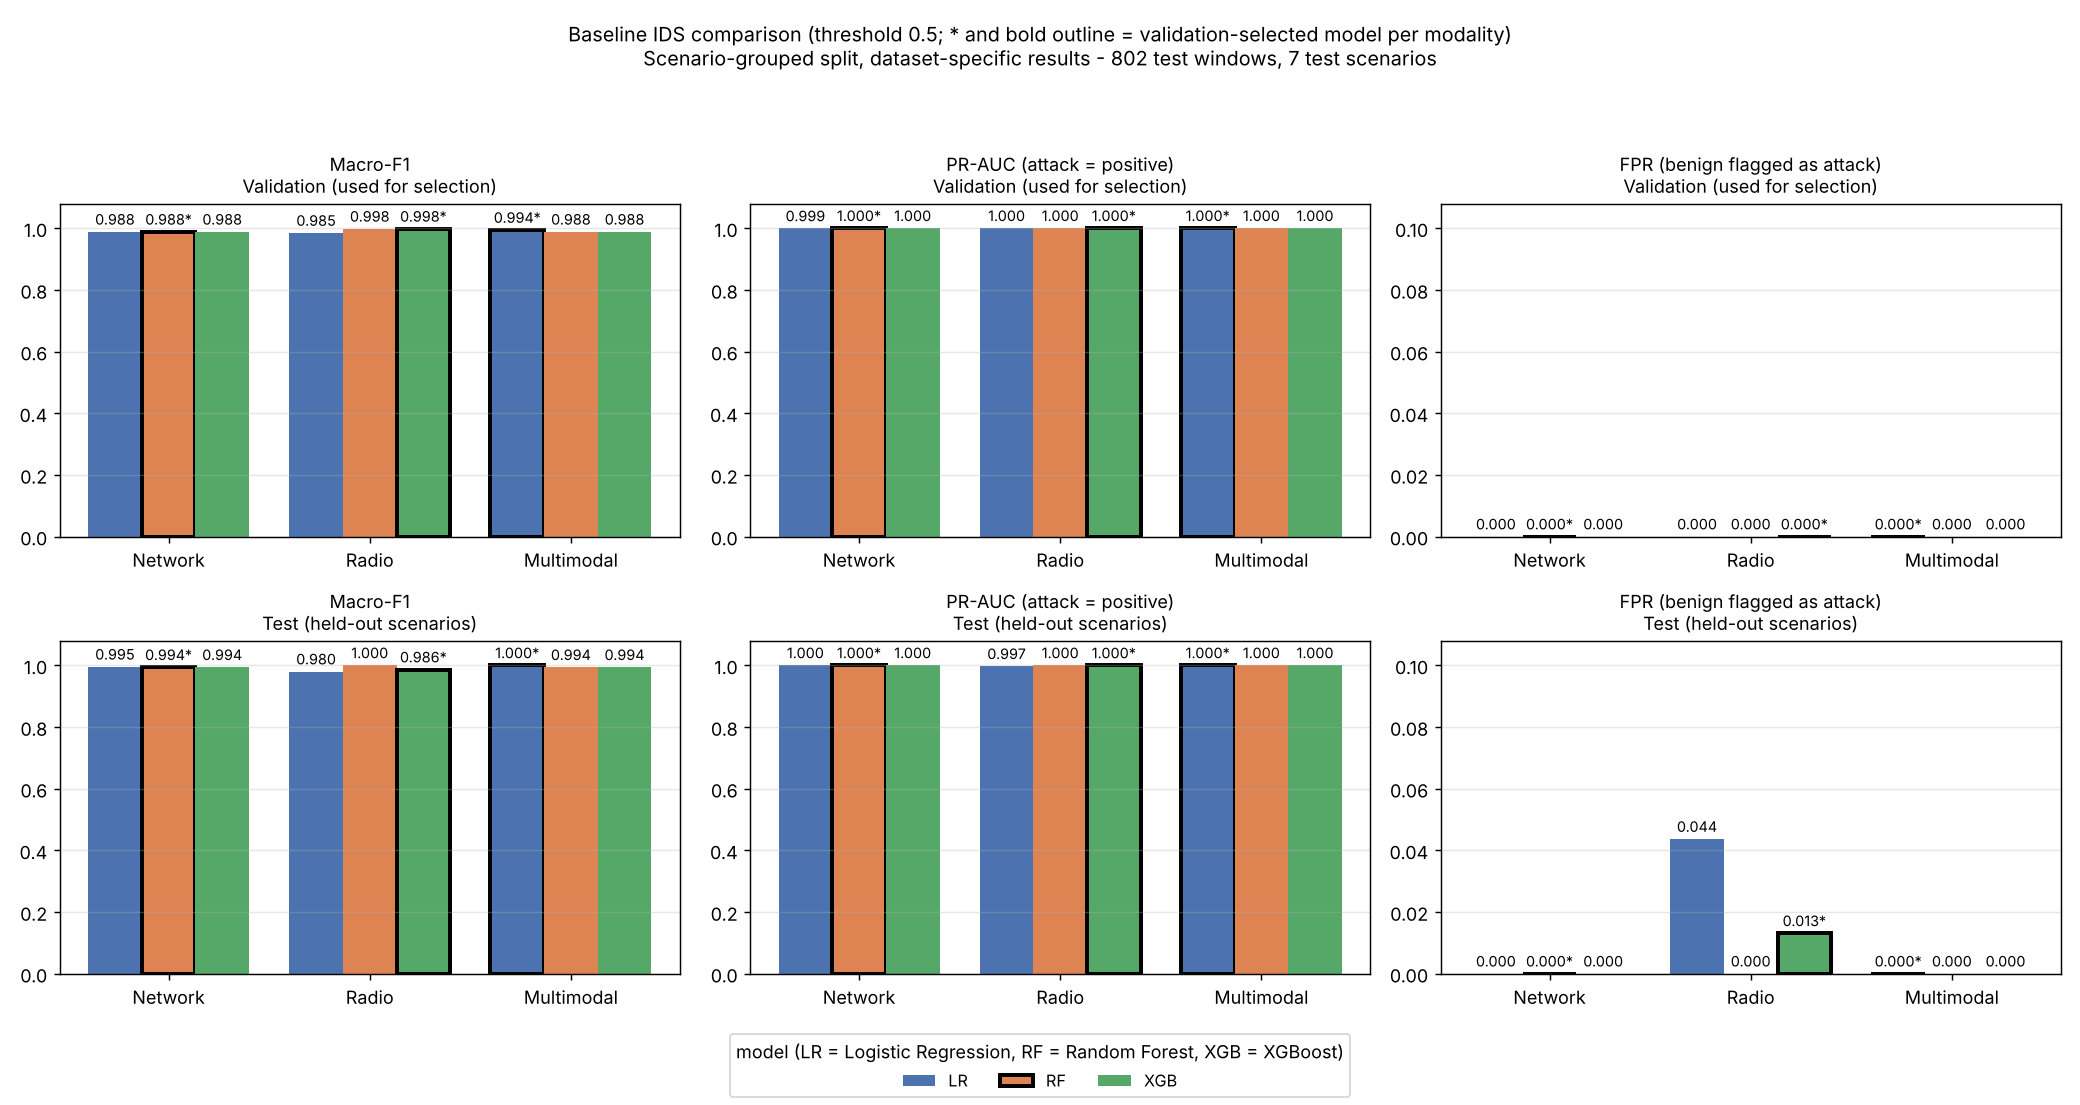

In [12]:
# ---- 7. Plots ---------------------------------------------------------------------------------------------------
COLORS = {"LogisticRegression": "#4C72B0", "RandomForest": "#DD8452", "XGBoost": "#55A868"}
def comparison_plot(res, path):
    mets = [("macro_f1", "Macro-F1"), ("pr_auc", "PR-AUC (attack = positive)"), ("fpr", "FPR (benign flagged as attack)")]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
    x = np.arange(len(MODALITIES)); w = 0.8 / len(MODEL_ORDER)
    for r, (part, ptitle) in enumerate([("val", "Validation (used for selection)"), ("test", "Test (held-out scenarios)")]):
        for c, (mk, mt) in enumerate(mets):
            ax = axes[r, c]
            top = max(1.0, 1.0) if mk != "fpr" else max(0.1, 1.25 * res[f"{part}_{mk}"].max())
            for j, model in enumerate(MODEL_ORDER):
                vals = [float(res[(res.modality == m) & (res.model == model)][f"{part}_{mk}"].iloc[0]) for m in MODALITIES]
                sel = [bool(res[(res.modality == m) & (res.model == model)]["selected"].iloc[0]) for m in MODALITIES]
                bars = ax.bar(x + j * w - 0.4 + w / 2, vals, w, label=MODEL_SHORT[model], color=COLORS[model], edgecolor=["black" if s else "none" for s in sel],
                              linewidth=[2.2 if s else 0 for s in sel])
                for b, v, s in zip(bars, vals, sel):
                    ax.text(b.get_x() + b.get_width() / 2, v + top * 0.012, f"{v:.3f}" + ("*" if s else ""), ha="center", va="bottom", fontsize=8)
            ax.set_xticks(x); ax.set_xticklabels([m.capitalize() for m in MODALITIES]); ax.set_ylim(0, top * 1.08)
            ax.set_title(f"{mt}\n{ptitle}", fontsize=10); ax.grid(axis="y", alpha=0.3)
    fig.suptitle("Baseline IDS comparison (threshold 0.5; * and bold outline = validation-selected model per modality)\n"
                 f"Scenario-grouped split, dataset-specific results - {len(idx_te):,} test windows, {len(set(groups_all[idx_te]))} test scenarios", fontsize=11)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=len(MODEL_ORDER), title="model (LR = Logistic Regression, RF = Random Forest, XGB = XGBoost)", fontsize=9)
    fig.tight_layout(rect=[0, 0.07, 1, 0.94]); fig.savefig(path, dpi=130); plt.close(fig)
comparison_plot(RESULTS, RESULTS_DIR / "baseline_comparison.png")
from IPython.display import Image
display(Image(filename=str(RESULTS_DIR / "baseline_comparison.png")))

## 8. Save the artifacts
Selected model pipelines (`Models/*.pkl`, `joblib` format; the complete `Pipeline`, i.e. imputer + scaler/estimator), results, tuning log, per-modality test predictions.
The pickles depend on the library versions printed above and should be loaded with the same major versions.

In [13]:
# ---- 8. Save --------------------------------------------------------------------------------------------------
MODEL_FILES = {"network": "network_model.pkl", "radio": "radio_model.pkl", "multimodal": "multimodal_model.pkl"}
PRED_FILES = {m: f"{m}_test_predictions.csv" for m in MODALITIES}
for m in MODALITIES:
    joblib.dump(EXPERIMENTS[m]["best"][SELECTION[m]["model"]]["pipeline"], MODELS_DIR / MODEL_FILES[m])
    p = TEST_PROBA[(m, SELECTION[m]["model"])]
    pred = pd.DataFrame({"row_index": idx_te, "sample_id": df["window_id"].to_numpy()[idx_te], "scenario": df["scenario"].to_numpy()[idx_te],
                         "partition": "test", "y_true": yte, "y_pred": (p >= THRESHOLD).astype(int), "p_attack": p, "model": SELECTION[m]["model"]})
    pred.to_csv(RESULTS_DIR / PRED_FILES[m], index=False, lineterminator="\n")
RESULTS.to_csv(RESULTS_DIR / "baseline_results.csv", index=False, lineterminator="\n")
TUNING_LOG = pd.concat([EXPERIMENTS[m]["tuning"] for m in MODALITIES], ignore_index=True)
TUNING_LOG.to_csv(RESULTS_DIR / "tuning_log.csv", index=False, lineterminator="\n")
for f in sorted(list(MODELS_DIR.glob("*")) + list(RESULTS_DIR.glob("*"))):
    print(f"{str(f.relative_to(ROOT)):42s} {f.stat().st_size:>10,d} bytes")

Models/multimodal_model.pkl                     5,073 bytes
Models/network_model.pkl                      504,770 bytes
Models/radio_model.pkl                        206,541 bytes
Results/baseline_comparison.png               229,265 bytes
Results/baseline_results.csv                    3,211 bytes
Results/multimodal_test_predictions.csv        61,732 bytes
Results/network_test_predictions.csv           46,695 bytes
Results/radio_test_predictions.csv             46,294 bytes
Results/split_manifest.csv                    240,821 bytes
Results/tuning_log.csv                          9,076 bytes


## 9. Final verification (all checks must pass)
Re-reads everything **from disk** (manifest, prediction CSVs, pickled models) rather than trusting in-memory objects:
identical sample IDs and split across modalities - no scenario overlap - no leakage (also in the *fitted* pipelines) - models load and reproduce the saved predictions -
predictions match the right test rows - training-only preprocessing - selection used validation only - Member 1/2 files untouched.

In [14]:
# ---- 9. Verification --------------------------------------------------------------------------------------------
VER = []
def chk(name, ok, detail=""): VER.append({"check": name, "passed": bool(ok), "detail": str(detail)})

man = pd.read_csv(RESULTS_DIR / "split_manifest.csv")
preds = {m: pd.read_csv(RESULTS_DIR / PRED_FILES[m]) for m in MODALITIES}
tr_rows = man.index[man.partition == "train"].to_numpy(); va_rows = man.index[man.partition == "validation"].to_numpy(); te_rows = man.index[man.partition == "test"].to_numpy()

# 1. identical sample IDs and split assignments across the three modalities
chk("1a. the three prediction files list identical test sample IDs in identical order",
    list(preds["network"]["sample_id"]) == list(preds["radio"]["sample_id"]) == list(preds["multimodal"]["sample_id"]))
chk("1b. test sample IDs == manifest test rows (no more, no fewer)",
    set(preds["network"]["sample_id"]) == set(man.loc[man.partition == "test", "sample_id"]) and len(preds["network"]) == len(te_rows))
chk("1c. all three experiments were trained/validated on the same split (fingerprint) and it equals the saved manifest",
    len({EXPERIMENTS[m]["split_fingerprint"] for m in MODALITIES}) == 1
    and hashlib.sha256("".join(man["partition"]).encode()).hexdigest() == SPLIT_FINGERPRINT)
chk("1d. every prediction row carries partition 'test' matching the manifest",
    all((preds[m]["partition"] == "test").all() and (man.loc[preds[m]["row_index"], "partition"].to_numpy() == "test").all() for m in MODALITIES))
chk("1e. manifest: every dataset row appears exactly once and sample_id == window_id of that row",
    len(man) == len(df) and man["row_index"].is_unique and (man["sample_id"].to_numpy() == df["window_id"].to_numpy()).all())
chk("1f. partition sizes (windows)", True, dict(man["partition"].value_counts()))

# 2. no scenario overlap across partitions
S = {p: set(man.loc[man.partition == p, "scenario"]) for p in ("train", "validation", "test")}
chk("2a. no scenario appears in more than one partition", not (S["train"] & S["validation"]) and not (S["train"] & S["test"]) and not (S["validation"] & S["test"]),
    {p: len(s) for p, s in S.items()})
chk("2b. both classes present in train, validation and test", all(man.loc[man.partition == p, "is_attack"].nunique() == 2 for p in S))
chk("2c. test-prediction scenarios are test-only scenarios", all(set(preds[m]["scenario"]) <= S["test"] for m in MODALITIES))

# 3. no feature leakage (names + the FITTED pipelines' own input columns)
loaded = {m: joblib.load(MODELS_DIR / MODEL_FILES[m]) for m in MODALITIES}
for m in MODALITIES:
    fn = list(loaded[m].feature_names_in_)
    chk(f"3. [{m}] fitted pipeline uses exactly the approved {len(FEATURE_SETS[m])} features and no forbidden column",
        fn == FEATURE_SETS[m] and not leakage_problems(fn), f"{len(fn)} inputs")
chk("3b. feature counts are 29 / 32 / 61", [len(FEATURE_SETS[m]) for m in MODALITIES] == [29, 32, 61])
chk("3c. no approved feature is a copy of the label", not any(np.array_equal(df[c].to_numpy(float), y_all.astype(float)) for c in MM_FEATURES))

# 4. model files can be loaded and reproduce the saved predictions
for m in MODALITIES:
    try:
        pipe = loaded[m]; Xt = df.iloc[preds[m]["row_index"]][FEATURE_SETS[m]]
        p2 = pipe.predict_proba(Xt)[:, 1]
        ok4, det4 = isinstance(pipe, Pipeline) and np.allclose(p2, preds[m]["p_attack"].to_numpy(), atol=1e-12), f"{SELECTION[m]['model']}"
    except Exception as e:
        ok4, det4 = False, "prediction with the approved feature list failed: " + repr(e)[:140]
    chk(f"4. [{m}] {MODEL_FILES[m]} loads as a Pipeline and reproduces p_attack in the prediction CSV", ok4, det4)

# 5. prediction CSVs correspond to the correct test rows
for m in MODALITIES:
    pr = preds[m]; ri = pr["row_index"].to_numpy()
    chk(f"5. [{m}] sample_id / scenario / y_true match the dataset rows; y_pred == (p_attack >= {THRESHOLD})",
        (pr["sample_id"].to_numpy() == df["window_id"].to_numpy()[ri]).all() and (pr["scenario"].to_numpy() == df["scenario"].to_numpy()[ri]).all()
        and (pr["y_true"].to_numpy() == y_all[ri]).all() and (pr["y_pred"].to_numpy() == (pr["p_attack"].to_numpy() >= THRESHOLD).astype(int)).all()
        and set(pr.columns) >= {"row_index", "sample_id", "scenario", "partition", "y_true", "y_pred", "p_attack"})

# 6. preprocessing was fitted on TRAINING data only
for m in MODALITIES:
    try:
        imp = loaded[m].named_steps["imputer"]; Xtr = df.iloc[tr_rows][FEATURE_SETS[m]]
        ok = imp.statistics_.shape == (len(FEATURE_SETS[m]),) and np.allclose(imp.statistics_, Xtr.median().to_numpy(), equal_nan=True)
        if ok and "scaler" in loaded[m].named_steps:
            sc = loaded[m].named_steps["scaler"]
            Xi = pd.DataFrame(imp.transform(Xtr), columns=FEATURE_SETS[m])
            ok = np.allclose(sc.mean_, Xi.mean().to_numpy()) and np.allclose(sc.scale_, Xi.std(ddof=0).replace(0, 1).to_numpy())
        det6 = ""
    except Exception as e:
        ok, det6 = False, repr(e)[:140]
    chk(f"6. [{m}] imputer (and scaler, if any) statistics equal those recomputed from the training partition only", ok, det6)

# 7. model selection used validation only; selection unchanged after test evaluation
def reselect(modality):
    t = TUNING_LOG[TUNING_LOG.modality == modality].reset_index(drop=True)
    best = None
    for i, r in t.iterrows():
        key = (-round(r["val_macro_f1"], 10), -round(r["val_pr_auc"], 10), round(r["val_fpr"], 10), round(r["val_log_loss"], 10), i)
        if best is None or key < best[0]: best = (key, r["model"], json.loads(r["params"]))
    return {"model": best[1], "params": best[2]}
chk("7a. re-running the selection rule on VALIDATION columns of the tuning log reproduces the saved selection",
    all(reselect(m) == {"model": SELECTION[m]["model"], "params": SELECTION[m]["params"]} for m in MODALITIES))
chk("7b. selection JSON identical before and after the test evaluation", json.dumps(SELECTION, sort_keys=True) == SELECTION_JSON)
chk("7c. tuning log contains no test columns", not any(c.startswith("test_") for c in TUNING_LOG.columns))
res_disk = pd.read_csv(RESULTS_DIR / "baseline_results.csv")
chk("7d. exactly one selected model per modality in baseline_results.csv", (res_disk.groupby("modality")["selected"].sum() == 1).all())

# 8. saved test metrics are reproducible from the prediction CSVs
ok8 = True
for m in MODALITIES:
    mt = compute_metrics(preds[m]["y_true"], preds[m]["p_attack"]); row = res_disk[(res_disk.modality == m) & res_disk.selected].iloc[0]
    ok8 &= all(np.isclose(mt[k], row[f"test_{k}"]) for k in ("macro_f1", "precision", "recall", "pr_auc", "fpr"))
chk("8. results CSV test metrics of the selected models equal metrics recomputed from the prediction CSVs", ok8)

# 9. Member 1 / Member 2 (and all other pre-existing) files are byte-identical
MANIFEST_AFTER = {str(p.relative_to(ROOT)): _sha(p) for p in _tracked()}
changed = [k for k in MANIFEST_BEFORE if MANIFEST_AFTER.get(k) != MANIFEST_BEFORE[k]]; added = [k for k in MANIFEST_AFTER if k not in MANIFEST_BEFORE]
chk("9. all pre-existing project files unchanged (SHA-256), none missing, none added outside Models/ and Results/",
    not changed and not added and set(MANIFEST_BEFORE) <= set(MANIFEST_AFTER), f"{len(MANIFEST_BEFORE)} files checked; changed={changed}; added={added}")

VERIFICATION = pd.DataFrame(VER)
display(VERIFICATION)
assert VERIFICATION["passed"].all(), VERIFICATION[~VERIFICATION["passed"]]
print(f"\nall {len(VERIFICATION)} verification checks passed")

,check,passed,detail
0,1a. the three prediction files list identical ...,True,
1,1b. test sample IDs == manifest test rows (no ...,True,
2,1c. all three experiments were trained/validat...,True,
3,1d. every prediction row carries partition 'te...,True,
4,1e. manifest: every dataset row appears exactl...,True,
5,1f. partition sizes (windows),True,"{'train': np.int64(2702), 'test': np.int64(802..."
6,2a. no scenario appears in more than one parti...,True,"{'train': 22, 'validation': 6, 'test': 7}"
7,"2b. both classes present in train, validation ...",True,
8,2c. test-prediction scenarios are test-only sc...,True,
9,3. [network] fitted pipeline uses exactly the ...,True,29 inputs



all 29 verification checks passed


## 10. Report (`Results/baseline_report.md`)
Generated from the executed notebook; every number comes from this run.

In [15]:
# ---- 10. Report -------------------------------------------------------------------------------------------------
def _f(v, nd=4):
    if isinstance(v, (bool, np.bool_)): return "yes" if v else "no"
    if isinstance(v, (int, np.integer)): return f"{int(v):,}"
    if isinstance(v, (float, np.floating)): return "NaN" if np.isnan(v) else f"{v:.{nd}f}"
    return str(v)
def md_table(d, index=False, nd=4):
    if index: d = d.reset_index()
    cols = [str(c) for c in d.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for row in d.itertuples(index=False): out.append("| " + " | ".join(_f(v, nd) for v in row) + " |")
    return "\n".join(out)

R = RESULTS.copy(); sel = R[R.selected].set_index("modality").loc[MODALITIES]
tei = PART_TABLE.loc["test"]; vai = PART_TABLE.loc["validation"]; tri = PART_TABLE.loc["train"]
benign_dates = sorted(SCN_ASSIGN.loc[SCN_ASSIGN["mode"] == "Benign", "capture_date_utc"].unique()); attack_dates = sorted(SCN_ASSIGN.loc[SCN_ASSIGN["mode"] != "Benign", "capture_date_utc"].unique())
overlap_dates = sorted(set(benign_dates) & set(attack_dates))
val_best = {m: float(TUNING_LOG[TUNING_LOG.modality == m]["val_macro_f1"].max()) for m in MODALITIES}
val_worst = {m: float(TUNING_LOG[TUNING_LOG.modality == m]["val_macro_f1"].min()) for m in MODALITIES}
n_near_best = {m: int((TUNING_LOG[TUNING_LOG.modality == m]["val_macro_f1"] >= val_best[m] - 0.005).sum()) for m in MODALITIES}
n_cfg = {m: int((TUNING_LOG.modality == m).sum()) for m in MODALITIES}
test_benign_scn = sorted(SCN_ASSIGN[(SCN_ASSIGN.partition == "test") & (SCN_ASSIGN["mode"] == "Benign")].scenario)
val_benign_scn = sorted(SCN_ASSIGN[(SCN_ASSIGN.partition == "validation") & (SCN_ASSIGN["mode"] == "Benign")].scenario)
ps_part = SCN_ASSIGN[SCN_ASSIGN.class_fm == "PortScan"][["scenario", "partition", "windows"]]

L = []; A = L.append
A("# Baseline IDS Modeling Report (Member 3)"); A("")
A("**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*"); A("")
A("These are **dataset-specific baseline results** for a binary intrusion-detection task on one set of captures. They are **not** evidence that the models generalise to unseen 5G deployments, "
  "other capture sessions, other devices or other attack implementations. The network-radio alignment is at the UTC-second level only; **no packet-to-UE correspondence is claimed**."); A("")

A("## 1. Summary of results (test partition, validation-selected model per modality)"); A("")
summ = sel.reset_index()[["modality", "model", "hyperparameters", "val_macro_f1", "test_macro_f1", "test_precision", "test_recall", "test_pr_auc", "test_fpr", "test_tn", "test_fp", "test_fn", "test_tp"]]
A(md_table(summ)); A("")
A(f"Attack is the **positive class**. Precision/recall/FPR refer to the attack class; FPR = FP / (FP + TN), the share of Benign windows flagged as attack. Threshold 0.5. "
  f"PR-AUC (average precision) has a chance level equal to the attack prevalence of the evaluated partition (test: {tei['attack_share']:.3f}).")
A(""); A("![comparison](baseline_comparison.png)"); A("")
A("Read these numbers together with section 8: on the test partition the Benign class is represented by "
  f"**{len(test_benign_scn)} scenario ({', '.join(test_benign_scn)}; {int(tei['benign_windows'])} windows)**, so the FPR is based on very few independent units and differences between models are small relative to that uncertainty.")
A("")

A("## 2. Design"); A("")
A(md_table(pd.DataFrame({"experiment": ["A. Network-only", "B. Radio-only", "C. Multimodal"], "features": [len(FEATURE_SETS[m]) for m in MODALITIES],
                         "source": ["network_feature_columns.json: feature_cols", "radio_feature_columns_v2.json: Profile A (conservative core)", "A + B (== multimodal_feature_columns_v2.json Profile A)"]}))); A("")
A(f"* Evaluation population: `Multimodal Datasets/multimodal_dataset_v2.csv`, {len(df):,} matched windows in {df['scenario'].nunique()} scenarios; identical rows and identical partition assignments for all three experiments.")
A("* Target: `is_attack` (0 = Benign, 1 = Attack). `class_fm` is used only for descriptive tables. Multiclass classification is not attempted (PortScan has only "
  f"{int(df['class_fm'].eq('PortScan').sum())} windows in 3 scenarios).")
A("* Not used as inputs: `network_features.csv` (augmented data), labels, scenario names/identifiers, timestamps/epochs/dates/time-zone/session metadata, diagnostics, radio quality flags, raw byte-counter deltas, `_nz` variants, "
  "held-out radio KPIs (RSRP, RSSI, RI, PHR), Profile B-only columns (SINR, CQI), sensitivity-only columns. The network column `bytes` is an approved network-window packet-volume feature, not a radio counter.")
A(f"* Leakage controls: a name/pattern guard on the feature lists (with a self-test) and a check of the *fitted* pipelines' input columns (section 9). Missing values in approved features: "
  + (", ".join(f"`{k}`: {int(v)}" for k, v in df[MM_FEATURES].isna().sum().items() if v) or "none") + f" ({int(df[MM_FEATURES].isna().any(axis=1).sum())} windows).")
A(""); A("### Features"); A("")
A("**Network (29):** " + ", ".join(f"`{c}`" for c in NET_FEATURES)); A("")
A("**Radio Profile A (32):** " + ", ".join(f"`{c}`" for c in RADIO_FEATURES)); A("")

A("## 3. Train / validation / test split"); A("")
A("Scenario-grouped and stratified (`StratifiedGroupKFold`, stratified on `is_attack`, grouped by `scenario`): an outer 5-fold split provides the test partition, an inner 5-fold split of the remainder provides the validation partition. "
  f"{n_cand} (seed, outer fold, inner fold) candidates were enumerated (seeds 0-{SEARCH_SEEDS[-1]}); {len(feasible)} satisfied the hard constraints (both classes and a Benign scenario in every partition; at least one DoS and one DDoS scenario in validation and test) "
  f"and corresponded to {len(distinct)} distinct (validation, test) scenario assignments. The chosen candidate (seed {SPLIT_SEED}, outer fold {OUTER_FOLD}, inner fold {INNER_FOLD}) minimises a split-quality score computed "
  "**only from partition sizes and labels** (no model was trained when choosing the split). No row-random split is used. The exact assignment is in `split_manifest.csv`."); A("")
A(md_table(PART_TABLE, index=True)); A("")
A("Windows per `class_fm` and partition (descriptive):"); A(""); A(md_table(CLASS_BY_PART, index=True)); A("")
A("Scenario assignment (capture date is shown for transparency only; it is never a model input):"); A(""); A(md_table(SCN_ASSIGN)); A("")

A("## 4. Models and selection"); A("")
A("Logistic Regression, Random Forest" + (", XGBoost" if HAS_XGB else "") + ". Each is a scikit-learn `Pipeline` whose imputer (median) and scaler (Logistic Regression only) are fitted on the training partition only. "
  "Class imbalance is handled with class weights (`scale_pos_weight` for XGBoost). Threshold fixed at 0.5. Models are trained on the training partition only (not refit on train + validation), so the saved model is exactly the one that was validated and tested.")
if not HAS_XGB: A(""); A("**XGBoost was not available in this environment and was skipped.**")
A(""); A(f"Candidates per modality: {n_cfg['network']} (grid: LR C in {{0.01, 0.1, 1, 10}}; RF max_depth in {{5, 10, None}} x min_samples_leaf in {{1, 5}}" + ("; XGBoost max_depth in {3, 5} x learning_rate in {0.05, 0.1}" if HAS_XGB else "") + "). "
  "**Selection criterion (validation only):** macro-F1 (higher), then PR-AUC (higher), then FPR (lower), then log-loss (lower), then fixed grid order (LR < RF < XGBoost). "
  "The test partition was evaluated only after the selection was frozen; the full tuning log is `tuning_log.csv`.")
A(""); A("Selected configurations:"); A("")
A(md_table(pd.DataFrame([{"modality": m, "selected model": SELECTION[m]["model"], "hyperparameters": json.dumps(SELECTION[m]["params"]),
                          "validation macro-F1": float(sel.loc[m, "val_macro_f1"]), "validation PR-AUC": float(sel.loc[m, "val_pr_auc"]),
                          "validation macro-F1 range over all configs": f"{val_worst[m]:.4f} - {val_best[m]:.4f}",
                          "configs within 0.005 of the best": f"{n_near_best[m]} of {n_cfg[m]}"} for m in MODALITIES]))); A("")

A("## 5. Validation metrics (all models)"); A("")
A(md_table(R[["modality", "model", "selected", "val_macro_f1", "val_precision", "val_recall", "val_pr_auc", "val_fpr", "val_tn", "val_fp", "val_fn", "val_tp"]])); A("")
A("## 6. Test metrics (all models, same test windows)"); A("")
A(md_table(R[["modality", "model", "selected", "test_macro_f1", "test_precision", "test_recall", "test_pr_auc", "test_fpr", "test_tn", "test_fp", "test_fn", "test_tp"]])); A("")
A("Training times (`train_time_s` in `baseline_results.csv`, `fit_time_s` in `tuning_log.csv`) are machine-dependent and are therefore not repeated in this report.")
A(""); A("### Confusion matrices and classification reports (selected models, test; rows = true class, columns = predicted class)"); A("")
for m in MODALITIES:
    pr = preds[m]; cm = confusion_matrix(pr["y_true"], pr["y_pred"], labels=[0, 1])
    A(f"**{m.capitalize()}** - {SELECTION[m]['model']} {json.dumps(SELECTION[m]['params'])}"); A("")
    A(md_table(pd.DataFrame(cm, index=["true Benign (0)", "true Attack (1)"], columns=["pred Benign (0)", "pred Attack (1)"]).rename_axis("true \\ predicted"), index=True)); A("")
    A("```"); A(classification_report(pr["y_true"], pr["y_pred"], target_names=["Benign (0)", "Attack (1)"], digits=4, zero_division=0).rstrip()); A("```"); A("")

A("## 7. Exploratory analysis (not used for selection)"); A("")
A("Share of test windows predicted *attack* per test scenario by the selected model of each modality (Benign scenarios: the scenario's false-positive rate; attack scenarios: its recall):"); A("")
A(md_table(PER_SCN)); A("")
A("Descriptive single-feature separability in the **training** partition (symmetric ROC-AUC; no feature removed):"); A("")
A(md_table(SCREEN_SUMMARY, index=True)); A("")
A(md_table(SCREEN.sort_values("train_single_feature_auc", ascending=False).head(8))); A("")
hi = SCREEN[SCREEN.train_single_feature_auc >= 0.99]
A("Features with a single-feature training AUC >= 0.99: " + (", ".join(f"`{r.feature}` ({r.modality}, {r.train_single_feature_auc:.4f})" for r in hi.itertuples()) or "none") +
  ". A feature that almost separates the classes on its own means a high score does not by itself demonstrate attack-specific learning; this is a descriptive observation about the data, not a claim about any feature's cause.")
A("")

A("## 8. Limitations and research-integrity notes"); A("")
A(f"1. **Capture-date / session confounding is complete for the binary target.** All {len(SCN_ASSIGN[SCN_ASSIGN['mode'] == 'Benign'])} Benign scenarios were captured on {', '.join(benign_dates)}; attack scenarios were captured on {', '.join(attack_dates)}; "
  f"dates shared by both classes: {', '.join(overlap_dates) if overlap_dates else 'none'}. Capture date, UE population and radio/network session conditions therefore move together with the label. "
  "Scenario-grouped splitting prevents windows of one scenario from appearing in several partitions, but it **cannot remove** this confounding: a model can reach high scores by recognising capture conditions rather than attacks, "
  "and nothing here separates the two explanations. This applies most strongly to the radio and multimodal models.")
A(f"2. **Very few Benign scenarios.** Benign has {len(SCN_ASSIGN[SCN_ASSIGN['mode'] == 'Benign'])} scenarios in total: train {int(tri['benign_scenarios'])}, validation {int(vai['benign_scenarios'])} ({', '.join(val_benign_scn)}), test {int(tei['benign_scenarios'])} ({', '.join(test_benign_scn)}). "
  "False-positive rates are therefore estimated from very few independent units, windows within a scenario are strongly dependent, and no confidence interval is claimed.")
A(f"3. **One split.** All results come from a single scenario-grouped split ({len(distinct)} distinct validation/test assignments were feasible). Different splits could give different numbers; no repeated or nested cross-validation was run.")
A("4. **Near-ceiling scores; weak model ranking.** Validation macro-F1 over all tuned configurations spans " + "; ".join(f"{m}: {val_worst[m]:.4f}-{val_best[m]:.4f} ({n_near_best[m]} of {n_cfg[m]} within 0.005 of the best)" for m in MODALITIES)
  + f". On the test partition a single misclassified window changes recall by about {1 / int(tei['attack_windows']):.4f}, so differences between models and modalities of a few windows are not meaningful, "
    "and the validation set cannot reliably rank configurations that differ by that little; ties are resolved by the documented rule. The selected model is therefore not necessarily the best on test, and the test results were deliberately not used to change it.")
A(f"5. **Class prevalence.** Attack windows are the majority ({df[TARGET].mean():.1%}); PR-AUC should be read against that chance level, and macro-F1 / FPR give the Benign class equal weight.")
A("6. **Alignment.** Network and radio windows are paired by `(scenario, UTC second)`. Radio features aggregate several UEs; there is no packet ID or UE-to-flow mapping, so fusion is temporal and no packet-to-UE correspondence is claimed. Possible clock skew of a few seconds between sensors is unresolved.")
A("7. **Few PortScan windows.** PortScan has 8 windows in 3 scenarios (" + "; ".join(f"{r.scenario}: {r.partition}, {r.windows} windows" for r in ps_part.itertuples()) + "); any statement about PortScan is anecdotal.")
A("8. **Scope.** Fixed threshold (0.5), no probability calibration, small hyper-parameter grids, models trained on the training partition only. No telemetry manipulation, adversarial simulation, trust scoring, sensor-reliability mechanism or defense is implemented here.")
A("9. **Missing values.** The few missing radio statistics are imputed inside each pipeline with training-partition medians; no global imputation is performed.")
A("10. **Environment.** The `.pkl` files are `joblib` dumps of scikit-learn pipelines" + (" (XGBoost estimator included)" if HAS_XGB else "") + " and should be loaded with the library versions listed below.")
A(""); A("## 9. Verification performed by the notebook"); A("")
A(md_table(VERIFICATION[["passed", "check", "detail"]])); A("")
A("## 10. Reproducibility"); A("")
A(f"* Fixed seeds: model/NumPy/random seed {SEED}; split-search seeds 0-{SEARCH_SEEDS[-1]} (chosen seed {SPLIT_SEED}). Deterministic single-threaded estimators.")
A("* Environment:"); A(""); A(md_table(ENV_TABLE)); A("")
A("* Run from the project root: `jupyter nbconvert --to notebook --execute --inplace 04_baseline_models.ipynb` (or *Restart & Run All*). Inputs are read read-only; outputs go to `Models/` and `Results/` only.")
A("")
(RESULTS_DIR / "baseline_report.md").write_text("\n".join(L), encoding="utf-8")
print("report written:", (RESULTS_DIR / "baseline_report.md").stat().st_size, "bytes")

report written: 22137 bytes


## 11. Required artifacts and summary

In [16]:
# ---- 11. Artifact check + summary -------------------------------------------------------------------------------
REQUIRED = ["04_baseline_models.ipynb", "Models/network_model.pkl", "Models/radio_model.pkl", "Models/multimodal_model.pkl",
            "Results/baseline_results.csv", "Results/baseline_comparison.png", "Results/baseline_report.md", "Results/network_test_predictions.csv",
            "Results/radio_test_predictions.csv", "Results/multimodal_test_predictions.csv", "Results/split_manifest.csv"]
art = pd.DataFrame([{"artifact": r, "exists": (ROOT / r).exists() and (ROOT / r).stat().st_size > 0} for r in REQUIRED]); display(art)
assert art["exists"].all(), art[~art["exists"]]
print("\nSelected models (validation-selected) - TEST metrics, attack = positive class:")
display(RESULTS[RESULTS.selected][["modality", "model", "test_macro_f1", "test_precision", "test_recall", "test_pr_auc", "test_fpr"]].round(4))
print("ALL STEPS COMPLETED SUCCESSFULLY")

,artifact,exists
0,04_baseline_models.ipynb,True
1,Models/network_model.pkl,True
2,Models/radio_model.pkl,True
3,Models/multimodal_model.pkl,True
4,Results/baseline_results.csv,True
5,Results/baseline_comparison.png,True
6,Results/baseline_report.md,True
7,Results/network_test_predictions.csv,True
8,Results/radio_test_predictions.csv,True
9,Results/multimodal_test_predictions.csv,True



Selected models (validation-selected) - TEST metrics, attack = positive class:


,modality,model,test_macro_f1,test_precision,test_recall,test_pr_auc,test_fpr
1,network,RandomForest,0.9939,1.0000,0.9930,1.0000,0.0000
5,radio,XGBoost,0.9863,0.9947,0.9895,0.9997,0.0131
6,multimodal,LogisticRegression,1.0000,1.0000,1.0000,1.0000,0.0000


ALL STEPS COMPLETED SUCCESSFULLY
